# Buổi B6: Ridge và Lasso, kìm cương hệ số và chọn cột

**Hiện trường.** Chị Hạnh quay lại với hai nỗi lo từ các buổi trước:

- Ở B3, hai chỉ số **s1 và s2 "sinh đôi"** làm hệ số bấp bênh, ngược dấu nhau. Ở B5, thêm cột bậc cao (65 cột) làm điểm thi **tụt** từ 0,46 xuống 0,32. Chị hỏi: *"Có cách nào để giữ nhiều cột mà máy không vặn quá tay không?"*
- Mỗi chỉ số xét nghiệm đều tốn tiền. Chị hỏi tiếp: *"Có thể bỏ bớt chỉ số nào mà vẫn đoán tốt?"*

Hai câu hỏi, hai công cụ cùng một họ: **Ridge** (kìm cương hệ số) và **Lasso** (kìm cương và tự chọn cột).

**Câu hỏi của buổi này:** *thêm một "dây cương" lên các hệ số thì mô hình đổi thế nào, và chọn độ chặt của dây ra sao?*

**Mindset của người làm dữ liệu:** quá khớp có thể chữa không chỉ bằng cách *bớt cột*, mà bằng cách *bớt tự do* của hệ số. Và **độ chặt của dây cương** là một lựa chọn của ta, không phải thứ máy tự tìm.

**Lưu ý:** dữ liệu bệnh nhân là dữ liệu mẫu để học. Buổi này dùng lại cú pháp từ A1 đến B5 mà không giải thích lại.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Ý tưởng phạt: thêm dây cương vào cái bát |
| Chặng 2 | Ridge: hệ số co dần khi dây siết chặt |
| Chặng 3 | Ridge cứu mô hình 65 cột khỏi quá khớp |
| Chặng 4 | Lasso: dây cương kéo hệ số về đúng 0, tự chọn cột |
| Chặng 5 | Chọn độ chặt bằng kiểm định chéo (RidgeCV, LassoCV) |
| Chặng 6 | So sánh công bằng và phán quyết |

## Chặng 1: Ý tưởng phạt, thêm dây cương vào cái bát

**Câu hỏi:** quá khớp xảy ra khi hệ số được vặn **quá lớn** để khớp từng điểm nhiễu (hệ số `s1` −44 và `s2` +25 ở B3 triệt tiêu nhau, hay hệ số hàng trăm nghìn ở B5). Làm sao ngăn?

Ở B1, `fit` chọn hệ số làm **tổng bình phương sai lệch (SSE)** nhỏ nhất, hình cái bát. Ý tưởng mới: **cộng thêm một khoản phạt** cho hệ số lớn:

**tổng cần giảm = SSE + α × (độ lớn của hệ số)**

Hệ số nào muốn to thì phải đổi lại bằng sai lệch giảm đáng kể. Ký hiệu **α** (alpha) là **độ chặt của dây cương**: α = 0 là không phạt (hồi quy thường), α càng lớn dây càng chặt.

- **Ridge** đo độ lớn bằng **bình phương** hệ số.
- **Lasso** đo độ lớn bằng **trị tuyệt đối** hệ số.

Ta xem tác dụng bằng hình, với đúng một hệ số (độ dốc của BMI đã chuẩn hóa):

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

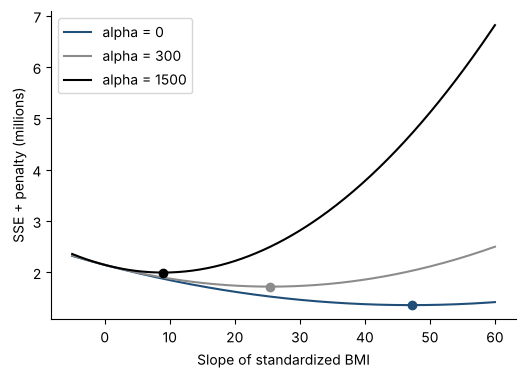

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
patients = load_diabetes(as_frame=True, scaled=False).frame
X = patients.drop(columns="target")
y = patients["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(X_train)
Z_train, Z_test = scaler.transform(X_train), scaler.transform(X_test)

z = Z_train[:, list(X.columns).index("bmi")]
slopes = np.linspace(-5, 60, 300)
sse = np.array([((y_train - y_train.mean() - b * z) ** 2).sum() for b in slopes])
for alpha, color in [(0, BLUE), (300, GRAY), (1500, "black")]:
    total = sse + alpha * slopes ** 2
    plt.plot(slopes, total / 1e6, color=color, label=f"alpha = {alpha}")
    plt.plot(slopes[np.argmin(total)], total.min() / 1e6, "o", color=color)
plt.xlabel("Slope of standardized BMI"); plt.ylabel("SSE + penalty (millions)")
plt.legend(); plt.show()

**Giải thích từng dòng**

- `from ... import ... (năm dòng đầu)`: (đã học) thêm `Ridge` và `Lasso` từ `linear_model`: hai thành viên mới của họ tuyến tính.
- `patients = ...; X, y = ...; train_test_split(...)`: (đã học) dữ liệu bệnh nhân, chia sổ hạt giống 42.
- `scaler = StandardScaler().fit(X_train); Z_train, Z_test = ...`: (đã học ở B4) chuẩn hóa: đo trên tập học, áp cho cả hai tập. `Z` là bảng đã chuẩn hóa (mảng numpy).
- `z = Z_train[:, list(X.columns).index("bmi")]`: lấy **cột BMI** đã chuẩn hóa: `[:, k]` là "mọi dòng, cột số k"; vị trí `k` tìm bằng `.index("bmi")` (đã học ở B3).
- `sse = np.array([((y_train - y_train.mean() - b * z) ** 2).sum() for b in slopes])`: (đã học) với mỗi độ dốc `b` thử, tính tổng bình phương sai lệch của đường *đi qua điểm trung bình*. Vì đã chuẩn hóa nên `intercept_` chính là trung bình `y` (B4), ta không cần thử nó.
- `total = sse + alpha * slopes ** 2`: **khoản phạt kiểu Ridge**: thêm α nhân bình phương độ dốc.
- `plt.plot(slopes[np.argmin(total)], total.min() / 1e6, "o", color=color)`: (đã học `argmin`) chấm tròn đánh dấu **đáy bát**: độ dốc được chọn.
- `/ 1e6`: chia cho một triệu cho số trên trục dọc gọn; `1e6` là cách viết 1.000.000.

**Cách đọc**

- **Con số:** đáy bát của α = 0 (xanh) nằm ở độ dốc khoảng **47**; ở α = 300 (xám) nằm quanh **25**; ở α = 1500 (đen) nằm quanh **9**.
- **Bức tranh:** càng tăng α, đáy bát bị **kéo về phía 0** (về bên trái), và bát hẹp hơn, sâu hơn. Máy vẫn đi tìm đáy như cũ, chỉ là cái bát nay có thêm *dốc phụ* kéo về 0. Hệ số muốn lớn phải "trả tiền" bằng khoản phạt.
- **Hệ quả:** hệ số **co lại** (không bao giờ lớn hơn lúc không phạt). Hệ số co nhỏ nghĩa là mô hình **ít chạy theo nhiễu** và **bớt nhạy** khi dữ liệu thay đổi chút ít.

**Hai loại tham số, đừng lẫn:**

| | Ví dụ | Ai quyết định |
|---|---|---|
| **Tham số** (parameter) | `coef_`, `intercept_` | **Máy học** từ dữ liệu khi `fit` |
| **Siêu tham số** (hyperparameter) | `alpha`, `degree`, `test_size` | **Ta chọn** trước khi `fit` |

`alpha` là siêu tham số: máy không tự biết nên siết bao chặt. Ta phải chọn, bằng kiểm định (chặng 5).

**Mang về chặng 1:** Ridge/Lasso = hồi quy thường + **khoản phạt** cho hệ số lớn, với độ chặt α (siêu tham số). Phạt kéo hệ số co về 0, giúp mô hình bớt chạy theo nhiễu.

## Chặng 2: Ridge, hệ số co dần khi dây siết chặt

**Câu hỏi:** với mười hệ số thật, khi tăng α chúng đi đâu?

Một quy tắc quan trọng: khoản phạt cộng **độ lớn** các hệ số, nên hệ số của cột có đơn vị nhỏ (cần hệ số lớn) sẽ bị phạt oan. Vì vậy **phải chuẩn hóa dữ liệu trước khi dùng Ridge hoặc Lasso** (B4 đã nói: đây là loại mô hình "nhạy thang đo").

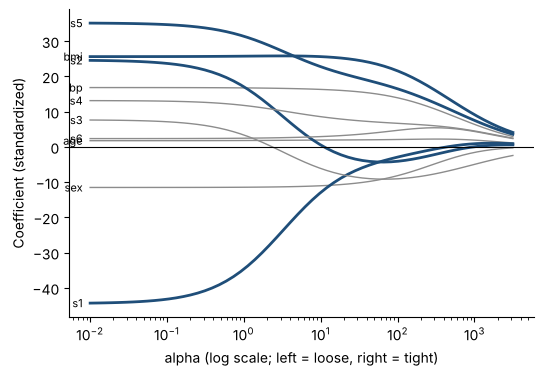

In [3]:
alphas = np.logspace(-2, 3.5, 60)
paths = np.array([Ridge(alpha=a).fit(Z_train, y_train).coef_ for a in alphas])
for k, name in enumerate(X.columns):
    highlight = name in ("s1", "s2", "s5", "bmi")
    plt.plot(alphas, paths[:, k], color=BLUE if highlight else GRAY, linewidth=2 if highlight else 1)
    plt.text(alphas[0] * 0.8, paths[0, k], name, ha="right", va="center", fontsize=8)
plt.xscale("log"); plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("alpha (log scale; left = loose, right = tight)"); plt.ylabel("Coefficient (standardized)")
plt.show()

**Giải thích từng dòng**

- `alphas = np.logspace(-2, 3.5, 60)`: **mới:** `np.logspace(a, b, n)` tạo `n` số cách đều nhau **theo thang logarit** từ 10^a đến 10^b (ở đây từ 0,01 đến khoảng 3000). Hợp với siêu tham số như `alpha`, vì ta quan tâm tới *bậc* của nó (0,01; 0,1; 1; 10; 100...), không quan tâm khoảng cách cộng.
- `paths = np.array([Ridge(alpha=a).fit(Z_train, y_train).coef_ for a in alphas])`: **mới:** `Ridge(alpha=a)` là máy Ridge với độ chặt `a`; `.fit` và `.coef_` như thường. List comprehension học **60 mô hình**, mỗi α một cái, rồi xếp hệ số vào bảng 60 dòng × 10 cột.
- `for k, name in enumerate(X.columns):`: **mới:** `enumerate(danh_sách)` cho **cả số thứ tự `k` lẫn phần tử `name`** trong mỗi vòng lặp: tiện khi cần chỉ số cột (`paths[:, k]`) và tên cột cùng lúc.
- `highlight = name in ("s1", "s2", "s5", "bmi")`: `in` hỏi "có nằm trong nhóm không" (Đúng/Sai). Bốn cột này được tô **đậm xanh**, các cột khác xám mảnh.
- `plt.text(alphas[0] * 0.8, paths[0, k], name, ...)`: (đã học `plt.text`) viết **tên cột ở đầu bên trái** của mỗi đường.
- `plt.xscale("log")`: (đã học ở B5) trục ngang theo thang log.

**Cách đọc**

- **Con số:** ở α rất nhỏ (bên trái), hệ số là của hồi quy thường: `s1` khoảng **−44**, `s2` khoảng **+25**, `s5` khoảng +35, `bmi` khoảng +26. Khi α đạt 10: `s1` còn khoảng **−13** và `s2` khoảng **0,5**; ở α = 100: cả hai co xuống cỡ **−3** và **−4**. Ở α = 1000, hệ số co rất mạnh (`bmi` còn khoảng 9, `s5` còn khoảng 7,5, `s2` về sát 0) nhưng vẫn chưa đúng bằng 0.
- **Bức tranh:** các đường **co dần về trục 0** như những sợi dây thun được kéo. Nhìn kỹ cặp sinh đôi `s1` (−44) và `s2` (+25): chúng **tiến lại nhau** và về gần 0 *cùng lúc*, thay vì kéo co nhau ở hai thái cực. Trong khi `bmi` và `s5` (hai cột "khỏe") **co chậm hơn** nhiều.
- **Ý nghĩa:** Ridge **chia đều công** giữa các cột tương quan thay vì để một cột "gánh âm" và một cột "gánh dương". Đó là cách nó giải quyết vấn đề đa cộng tuyến của B3: **ổn định hơn**, tuy không làm hệ số "đúng hơn" về mặt giải thích.
- **Ridge không bao giờ đưa hệ số về đúng 0**: chỉ nhỏ dần. Để loại hẳn một cột, cần Lasso (chặng 4).

In [4]:
table = pd.DataFrame({f"alpha={a}": Ridge(alpha=a).fit(Z_train, y_train).coef_ for a in [0.01, 1, 10, 100, 1000]}, index=X.columns).round(1)
table

,alpha=0.01,alpha=1,alpha=10,alpha=100,alpha=1000
age,1.8,1.8,1.9,2.1,1.9
sex,-11.5,-11.4,-11.0,-8.2,-1.6
bmi,25.6,25.7,25.6,21.6,9.1
bp,16.8,16.7,16.3,13.9,6.4
s1,-44.3,-34.7,-12.9,-2.9,0.9
s2,24.5,17.1,0.5,-4.1,0.0
s3,7.6,3.4,-6.1,-9.1,-5.0
s4,13.1,11.8,8.6,6.7,4.5
s5,35.1,31.4,22.7,16.5,7.5
s6,2.4,2.5,2.9,4.7,4.4


**Giải thích từng dòng**

- `pd.DataFrame({f"alpha={a}": ... for a in [...]}, index=X.columns)`: **mới:** `{khóa: giá_trị for a in ...}` là **dict comprehension**: giống list comprehension nhưng tạo ra **từ điển**. Mỗi α thành một cột của bảng, tên cột ghi bằng f-string.

**Cách đọc:** bảng xác nhận con số ở hình: hàng `s1` đi từ −44,3 xuống −34,7, −12,9, −2,9, 0,9 khi α tăng từ 0,01 đến 1000; hàng `s2` đi từ 24,5 xuống 17,1, 0,5, −4,1, 0,0. Chú ý `s2` **đổi dấu** trên đường đi: một lần nữa nhắc rằng *dấu của hệ số cặp sinh đôi không đáng tin*.

**Mang về chặng 2:** Ridge **co mọi hệ số** về 0 khi α tăng, nhưng không bằng 0 hẳn; nó chia đều công giữa các cột tương quan và làm hệ số ổn định hơn. **Bắt buộc chuẩn hóa trước.**

## Chặng 3: Ridge cứu mô hình 65 cột khỏi quá khớp

**Câu hỏi:** ở B5, mô hình đa thức bậc 2 với 65 cột có R² train 0,62 nhưng R² thi chỉ 0,32. Ridge cứu được không?

Ta lặp 20 lần chia sổ cho mỗi α (như thói quen từ A4) và theo dõi R² train và thi:

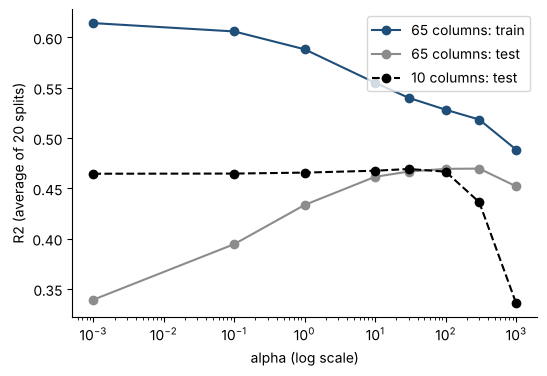

,alpha,train R2,test R2
0,0.001,0.614,0.339
1,0.100,0.606,0.395
2,1.000,0.588,0.434
3,10.000,0.555,0.462
4,30.000,0.540,0.467
5,100.000,0.528,0.469
6,300.000,0.518,0.470
7,1000.000,0.489,0.452


In [5]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
def ridge_curve(degree, alphas):
    rows = []
    for alpha in alphas:
        train_r2, test_r2 = [], []
        for seed in range(20):
            a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=seed)
            m = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), Ridge(alpha=alpha)).fit(a, c)
            train_r2.append(m.score(a, c)); test_r2.append(m.score(b, d))
        rows.append({"alpha": alpha, "train R2": np.mean(train_r2), "test R2": np.mean(test_r2)})
    return pd.DataFrame(rows)

alpha_grid = [0.001, 0.1, 1, 10, 30, 100, 300, 1000]
poly2 = ridge_curve(2, alpha_grid)
poly1 = ridge_curve(1, alpha_grid)
plt.plot(poly2["alpha"], poly2["train R2"], "o-", color=BLUE, label="65 columns: train")
plt.plot(poly2["alpha"], poly2["test R2"], "o-", color=GRAY, label="65 columns: test")
plt.plot(poly1["alpha"], poly1["test R2"], "o--", color="black", label="10 columns: test")
plt.xscale("log"); plt.xlabel("alpha (log scale)"); plt.ylabel("R2 (average of 20 splits)")
plt.legend(); plt.show()
poly2.round(3)

**Giải thích từng dòng**

- `from sklearn.preprocessing import PolynomialFeatures`: (đã học ở B5).
- `def ridge_curve(degree, alphas):`: gói thí nghiệm "lặp 20 lần chia và đo R² train và thi cho từng α" thành hàm, vì ta chạy hai lần (bậc 2 và bậc 1).
- `make_pipeline(PolynomialFeatures(...), StandardScaler(), Ridge(alpha=alpha)).fit(a, c)`: pipeline ba bước: sinh cột đa thức, chuẩn hóa, Ridge. Pipeline tự lo thứ tự và quy tắc "học chỉ từ tập học" mỗi lần chia.
- `poly2 = ridge_curve(2, alpha_grid); poly1 = ridge_curve(1, alpha_grid)`: bậc 2 (65 cột) và bậc 1 (10 cột gốc).

**Cách đọc**

- **Con số:** khi α rất nhỏ (gần hồi quy thường), mô hình 65 cột có R² train **0,61** và R² thi **0,34**: quá khớp như B5. Khi α tăng lên 30, R² thi leo lên **0,467**; ở α từ 100 đến 300, R² thi đạt đỉnh **0,47** (trong khi R² train tụt xuống 0,52 đến 0,53). Đường 10 cột (đen đứt) chỉ nhích từ 0,465 lên đỉnh 0,469 quanh α = 30.
- **Bức tranh:** hai đường xanh (train) và xám (test) của mô hình 65 cột từ chỗ **xòe ra như cái kéo** khi α nhỏ, **khép lại** khi α tăng: đường train đi xuống, đường test đi lên rồi gặp nhau ở chỗ cao nhất. Đây là điều ngược với chặng 3 của B5: lần này ta *giảm tự do* thay vì giảm số cột.
- **Một điều thành thật:** Ridge cứu mô hình 65 cột từ 0,34 lên 0,47, ngang đỉnh của mô hình **đơn giản 10 cột** (0,469). *Ridge không biến 65 cột thành giỏi hơn 10 cột*; nó chỉ **cứu** mô hình khỏi chuyện tệ. Trên bài này, mô hình đơn giản vốn đã gần như đủ tốt. Đừng mong Ridge làm phép màu khi dữ liệu không có thêm thông tin để cho.
- **Khi α quá lớn** (1000 trở lên) cả hai đường tụt: mô hình bị siết quá chặt, thành **dưới khớp**. Có một vùng α "vừa đủ".

**Mang về chặng 3:** Ridge chữa quá khớp do nhiều cột: R² train hạ, R² thi tăng, hai đường khép lại. Nhưng nó chỉ đưa mô hình phức tạp về ngang mô hình đơn giản khi dữ liệu không đủ thông tin; α quá lớn thì thành dưới khớp.

## Chặng 4: Lasso, dây cương kéo hệ số về đúng 0, tự chọn cột

**Câu hỏi:** chị Hạnh muốn bỏ bớt chỉ số xét nghiệm. Có công cụ nào *tự chọn* cột không?

**Lasso** phạt bằng **trị tuyệt đối** thay vì bình phương. Khác biệt nhỏ về công thức, nhưng hệ quả lớn: khoản phạt trị tuyệt đối có "góc nhọn" tại 0, nên khi α đủ lớn, hệ số bị **kẹt cứng ở đúng 0**. Cột có hệ số 0 coi như **bị loại khỏi mô hình**.

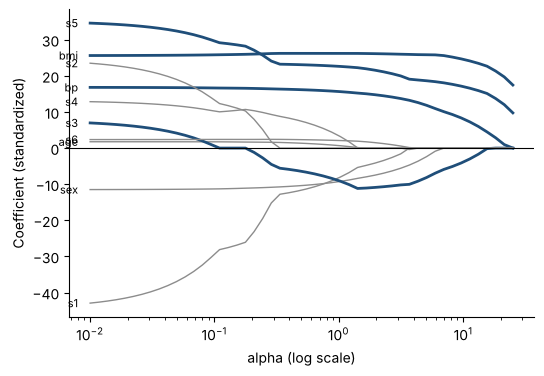

,alpha,non-zero columns
0,0.01,10
15,0.11,9
25,0.54,9
32,1.66,7
38,4.33,5
44,11.30,4
49,25.12,2


In [6]:
lasso_alphas = np.logspace(-2, 1.4, 50)
lasso_paths = np.array([Lasso(alpha=a, max_iter=20000).fit(Z_train, y_train).coef_ for a in lasso_alphas])
for k, name in enumerate(X.columns):
    plt.plot(lasso_alphas, lasso_paths[:, k], color=BLUE if name in ("bmi", "s5", "bp", "s3") else GRAY, linewidth=2 if name in ("bmi", "s5", "bp", "s3") else 1)
    plt.text(lasso_alphas[0] * 0.8, lasso_paths[0, k], name, ha="right", va="center", fontsize=8)
plt.xscale("log"); plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("alpha (log scale)"); plt.ylabel("Coefficient (standardized)")
plt.show()
survivors = pd.DataFrame({"alpha": lasso_alphas, "non-zero columns": (lasso_paths != 0).sum(axis=1)})
survivors.iloc[[0, 15, 25, 32, 38, 44, 49]].round(2)

**Giải thích từng dòng**

- `Lasso(alpha=a, max_iter=20000)`: máy Lasso. `max_iter` (đã học ở A6) là số vòng luyện tối đa: Lasso giải bằng cách lặp nên cần đủ vòng; nếu thiếu, sklearn cảnh báo.
- `(lasso_paths != 0).sum(axis=1)`: so từng hệ số với 0 (Đúng/Sai), cộng theo **từng dòng** (`axis=1`): đếm **có bao nhiêu cột còn sống** ở mỗi α.
- `survivors.iloc[[0, 15, 25, 32, 38, 44, 49]]`: (đã học `iloc`) lấy bảy dòng rải đều để bảng gọn.

**Cách đọc**

- **Con số:** ở α nhỏ nhất (0,01), **cả 10 cột** còn sống. Khi α tăng, các hệ số lần lượt **chạm trục 0 rồi nằm yên ở đó**. Ở α khoảng 0,1 đến 0,5 còn **9** cột (`s2` về 0 đầu tiên); ở α khoảng 1,7 còn **7** cột; ở α khoảng 11 chỉ còn **4** cột: **`bmi`, `bp`, `s3`, `s5`**; ở α khoảng 25 còn **2** cột.
- **Bức tranh:** khác với Ridge (co dần nhưng không bao giờ chạm 0), các đường của Lasso **đâm thẳng xuống trục 0 rồi bám dính vào đó**. Thứ tự các cột *rời khỏi mô hình* cho ta một bảng xếp hạng: cột nào **ở lại lâu nhất** thì cột đó mạnh nhất. Ở đây: `s2` ra đầu tiên, rồi `age` và `s4`, sau đó là `s6`, `sex`, `s1`; còn `bmi`, `bp`, `s3`, `s5` trụ đến cuối.
- **Trả lời chị Hạnh:** bốn chỉ số là **BMI, huyết áp (bp), s3 và s5** giữ lại được phần lớn sức đoán. Hãy kiểm tra: R² thi của bốn cột đó là bao nhiêu?

In [7]:
for alpha in [0.1, 1, 3, 10]:
    lasso = Lasso(alpha=alpha, max_iter=20000).fit(Z_train, y_train)
    kept = X.columns[lasso.coef_ != 0].tolist()
    print(f"alpha={alpha:>4}: R2 test = {lasso.score(Z_test, y_test):.3f} | {len(kept)} columns kept: {kept}")

alpha= 0.1: R2 test = 0.456 | 10 columns kept: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
alpha=   1: R2 test = 0.467 | 9 columns kept: ['age', 'sex', 'bmi', 'bp', 's1', 's3', 's4', 's5', 's6']
alpha=   3: R2 test = 0.471 | 7 columns kept: ['sex', 'bmi', 'bp', 's1', 's3', 's5', 's6']
alpha=  10: R2 test = 0.446 | 4 columns kept: ['bmi', 'bp', 's3', 's5']


**Giải thích từng dòng**

- `lasso = Lasso(alpha=alpha, max_iter=20000).fit(Z_train, y_train)`: học Lasso ở từng α.
- `kept = X.columns[lasso.coef_ != 0].tolist()`: **mới:** dùng dãy Đúng/Sai (`coef_ != 0`: hệ số khác 0) để **lọc tên cột**: `X.columns[...]` giữ lại những tên ứng với Đúng. Đây là cách đọc "Lasso chọn cột nào".
- `f"alpha={alpha:>4}: ..."`: (đã học f-string) `:>4` căn số **phải** trong 4 ký tự; `:.3f` làm tròn 3 chữ số.

**Cách đọc**

- **Con số:** α = 0,1 giữ 10 cột, R² thi **0,456**. α = 1 giữ 9 cột, R² thi **0,467**. α = **3** giữ **7** cột (bỏ `age`, `s2`, `s4`), R² thi **0,471**: **tốt hơn** hồi quy thường mười cột (0,453). α = 10 chỉ giữ 4 cột (`bmi`, `bp`, `s3`, `s5`), R² thi **0,446**: tụt rất ít so với mười cột.
- **Bức tranh:** *bỏ ba cột mà điểm thi còn nhích lên* (0,453 lên 0,471), và *bỏ sáu cột chỉ mất 0,007*. Ba cột bỏ đầu tiên đúng là những cột đã được chặng 3 của B3 chỉ ra là **không góp gì thêm**. Lasso làm tự động điều ta làm thủ công ở B3.
- **Nhắc lại bài học B3:** việc Lasso *chọn* cột là chọn theo **sức đoán**, không phải kết luận về nguyên nhân. Với cặp sinh đôi `s1` và `s2`, Lasso thường **giữ một cái và bỏ cái kia** theo may rủi của mẫu; đừng đọc "s2 bị bỏ" thành "s2 vô dụng" (chặng 2 cho thấy nó có thể thay thế được cho `s1`).

**Mang về chặng 4:** Lasso kéo hệ số về **đúng 0**, tức là **tự chọn cột**. Cột ở lại lâu nhất khi α tăng là cột mạnh nhất. Với bệnh nhân, bốn cột (BMI, bp, s3, s5) giữ gần hết sức đoán của mười cột.

## Chặng 5: Chọn độ chặt bằng kiểm định chéo, RidgeCV và LassoCV

**Câu hỏi:** α bằng bao nhiêu là đúng? Ta vừa nhìn bảng để chọn. Có cách nào để máy chọn giúp, mà không dùng tập thi?

Ý tưởng **kiểm định chéo** (cross-validation, viết tắt CV): chia **tập học** thành k phần bằng nhau (ví dụ 5). Lần lượt, lấy **một phần làm tập kiểm định**, bốn phần còn lại để học; lặp 5 lần để *mỗi phần đều được làm kiểm định một lần*, rồi lấy trung bình điểm. Làm vậy cho mỗi α, chọn α có điểm trung bình tốt nhất. Tập thi vẫn **không bị chạm**. (Phần D sẽ đi sâu hơn.)

Sklearn có sẵn bản "tự chọn α": `RidgeCV` và `LassoCV`.

In [8]:
from sklearn.linear_model import RidgeCV, LassoCV
ridge_cv = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))).fit(X_train, y_train)
lasso_cv = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, max_iter=20000)).fit(X_train, y_train)
print("RidgeCV chose alpha =", round(ridge_cv[-1].alpha_, 2))
print("LassoCV chose alpha =", round(lasso_cv[-1].alpha_, 2))
print("Lasso kept:", X.columns[lasso_cv[-1].coef_ != 0].tolist())
print("Lasso dropped:", X.columns[lasso_cv[-1].coef_ == 0].tolist())

RidgeCV chose alpha = 1.17
LassoCV chose alpha = 1.66
Lasso kept: ['sex', 'bmi', 'bp', 's1', 's3', 's5', 's6']
Lasso dropped: ['age', 's2', 's4']


**Giải thích từng dòng**

- `from sklearn.linear_model import RidgeCV, LassoCV`: hai máy "tự chọn α bằng kiểm định chéo".
- `RidgeCV(alphas=np.logspace(-2, 3, 30))`: đưa cho nó **danh sách 30 α ứng viên**; máy thử từng α bằng kiểm định chéo trong tập học rồi chọn α tốt nhất.
- `LassoCV(cv=5, random_state=0, max_iter=20000)`: `cv=5` là số phần chia (5 phần như mô tả). Lasso tự sinh dãy α ứng viên; `random_state` là hạt giống cho cách chia.
- `ridge_cv[-1].alpha_`: (đã học `pipe[-1]` ở B4) lấy bước cuối; `alpha_` (gạch dưới cuối) là **α mà máy đã chọn**.
- `X.columns[lasso_cv[-1].coef_ == 0].tolist()`: lọc tên cột có hệ số bằng 0: những cột **bị loại**.

**Cách đọc**

- **Con số:** RidgeCV chọn **α khoảng 1,2** (rất nhỏ, vì với 10 cột quá khớp nhẹ). LassoCV chọn **α khoảng 1,7**; Lasso **giữ 7 cột, bỏ 3 cột** (`age`, `s2`, `s4`), đúng bộ ba mà ở chặng 4 ta thấy rời khỏi mô hình đầu tiên.
- **Bức tranh:** máy tự chọn gần đúng nơi ta chọn bằng mắt (α khoảng 1 đến 3). Nhưng quan trọng hơn là **cách chọn không nhìn trộm tập thi**: mọi quyết định đều nằm trong tập học.
- **Quy tắc:** *siêu tham số được chọn bằng kiểm định chéo trên tập học; tập thi chỉ chấm một lần ở cuối.* Đây là quy tắc áp dụng cho mọi siêu tham số (`alpha`, `degree`...) trong cả khóa.

## Chặng 6: So sánh công bằng và phán quyết

**Câu hỏi:** tổng hợp lại, mô hình nào dùng cho chị Hạnh?

Đặt cạnh nhau năm mô hình, trên cùng 89 bệnh nhân thi, với ba thước đo: MAE, R², và quyết định thật (điểm trung bình của 10 người được chọn).

In [9]:
def top10_mean(pred):
    return y_test.to_numpy()[np.argsort(-pred)[:10]].mean()

lasso_small = make_pipeline(StandardScaler(), Lasso(alpha=10, max_iter=20000)).fit(X_train, y_train)
poly_ridge = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge(alpha=200)).fit(X_train, y_train)
poly_plain = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()).fit(X_train, y_train)
contenders = {
    "plain 10 columns": make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train),
    "Ridge (CV)": ridge_cv,
    "Lasso (CV, 7 columns)": lasso_cv,
    "Lasso alpha=10 (4 columns)": lasso_small,
    "65 columns, no penalty": poly_plain,
    "65 columns + Ridge": poly_ridge,
}
board = pd.DataFrame({
    name: {"MAE": mean_absolute_error(y_test, m.predict(X_test)), "R2": m.score(X_test, y_test), "top-10 mean": top10_mean(m.predict(X_test))}
    for name, m in contenders.items()
}).T.round(3)
board

,MAE,R2,top-10 mean
plain 10 columns,42.794,0.453,256.5
Ridge (CV),42.814,0.454,256.5
"Lasso (CV, 7 columns)",42.793,0.471,250.1
Lasso alpha=10 (4 columns),44.765,0.446,245.8
"65 columns, no penalty",43.582,0.416,246.9
65 columns + Ridge,43.066,0.459,250.3


**Giải thích từng dòng**

- `def top10_mean(pred):`: (đã học ở B3) thước đo quyết định: điểm thật trung bình của 10 người có điểm đoán cao nhất.
- `lasso_small = ...; poly_ridge = ...; poly_plain = ...`: ba mô hình bổ sung: Lasso chặt (α = 10, còn 4 cột), mô hình 65 cột có Ridge (α = 200, chọn từ vùng đẹp ở chặng 3), và 65 cột không phạt.
- `contenders = {tên: mô_hình, ...}`: từ điển các thí sinh. Mô hình `ridge_cv` và `lasso_cv` từ chặng 5.
- `board = pd.DataFrame({name: {...} for name, m in contenders.items()}).T.round(3)`: (đã học dict comprehension) với mỗi mô hình ta tính ba thước đo ghi thành từ điển nhỏ; `pd.DataFrame` xếp mỗi mô hình thành một *cột*; `.T` **chuyển vị** (đã học ở B4) cho mỗi mô hình thành một *dòng*.

**Cách đọc**

- **Con số (hạt giống 42, 89 bệnh nhân thi):** mô hình mười cột thường: MAE 42,8, R² 0,453. RidgeCV: MAE 42,8, R² 0,454. LassoCV (7 cột): MAE 42,8, R² 0,471. Lasso α = 10 (4 cột): MAE 44,8, R² 0,446. Mô hình 65 cột không phạt: R² 0,416 (hạt giống 42; trung bình 20 lần chia chỉ khoảng 0,34, như chặng 3). Mô hình 65 cột có Ridge: R² 0,459.
- **Bức tranh:** năm mô hình đứng chung một khoảng hẹp (R² từ 0,446 đến 0,471); mô hình **65 cột không phạt** thấp nhất (0,416). Khác biệt giữa các mô hình "tốt" **nhỏ hơn mức dao động** do cách chia (A4). Ở thước đo **top 10**, mô hình mười cột thường lại cao nhất (256,5) so với Lasso 7 cột (250,1) và Lasso 4 cột (245,8): xếp hạng *đổi tùy thước đo*, đúng như bài học B2.
- **Một điều thành thật:** với 89 người thi, các chênh lệch 0,01 đến 0,02 ở trên **không phân biệt được** bằng một lần chia. Đừng tôn thờ bảng xếp hạng. Cái ta đọc ra là: *nhóm mô hình "có kiểm soát" đều ổn; mô hình không kiểm soát (65 cột trần) thì hỏng*.

## Phán quyết và bài học nghề

**Phán quyết cho chị Hạnh.**

- **Về độ ổn định:** dùng **Ridge** (hoặc Lasso) thay vì hồi quy thường khi có nhiều cột, đặc biệt khi các cột tương quan nhau. Hệ số ổn định hơn, nguy cơ quá khớp thấp hơn.
- **Về rút gọn xét nghiệm:** dùng **Lasso**. Mô hình **4 cột** (BMI, huyết áp, s3, s5) giữ gần hết sức đoán (R² thi 0,446 so với 0,453 của mười cột; chọn top 10 đạt 246 so với 256) và rẻ hơn nhiều. Cái giá là mất một chút ở top 10; ban giám đốc cần cân nhắc. Nếu cần tối đa hóa, giữ 7 cột (bỏ `age`, `s2`, `s4`).
- **Về lời khuyên đọc hệ số:** vẫn **không** kể chuyện nhân quả từ hệ số của cặp sinh đôi `s1`, `s2`.

**Bài học nghề.**

1. **Ridge và Lasso = hồi quy + khoản phạt cho hệ số lớn.** Độ chặt là `alpha` (siêu tham số).
2. **Phải chuẩn hóa trước.** Không chuẩn hóa thì khoản phạt bất công giữa các cột.
3. **Ridge co hệ số đều, ổn định cho cột tương quan; Lasso kéo hệ số về 0, tự chọn cột.**
4. **Tham số do máy học, siêu tham số do ta chọn.** Chọn bằng kiểm định chéo trên tập học (`RidgeCV`, `LassoCV`), không dùng tập thi.
5. **Phạt không tạo ra thông tin mới.** Nó chỉ cứu mô hình khỏi quá khớp, không làm mô hình giỏi hơn khi dữ liệu không đủ thông tin.

**Một điều thành thật:** chọn cột bằng Lasso dựa trên *một mẫu dữ liệu*; mẫu khác có thể chọn khác. Nếu quyết định quan trọng (cắt bỏ xét nghiệm tốn kém), hãy **lặp Lasso trên nhiều mẫu** và chỉ tin cột nào được chọn **hầu hết các lần**.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Ridge và Lasso: hồi quy thường cộng thêm khoản phạt cho hệ số lớn, với độ chặt `alpha` (siêu tham số). |
| 2 | Ridge co mọi hệ số về 0, không bao giờ bằng 0; chia đều công giữa các cột tương quan; bắt buộc chuẩn hóa. |
| 3 | Ridge chữa quá khớp do nhiều cột: R² train hạ, R² thi tăng; α quá lớn thành dưới khớp. |
| 4 | Lasso kéo hệ số về đúng 0, tự chọn cột; cột ở lại lâu nhất là cột mạnh nhất. |
| 5 | Chọn `alpha` bằng kiểm định chéo trên tập học (`RidgeCV`, `LassoCV`), không nhìn tập thi. |
| 6 | Phạt không tạo thông tin mới; chênh lệch nhỏ giữa các mô hình tốt thường nằm trong vùng nhiễu. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Dây cương siết hệ số theo bình phương | hồi quy Ridge (L2) | `Ridge(alpha=...)` |
| Dây cương siết hệ số theo trị tuyệt đối | hồi quy Lasso (L1) | `Lasso(alpha=...)` |
| Độ chặt của dây cương | siêu tham số alpha | `alpha=` |
| Thứ máy học từ dữ liệu | tham số | `coef_`, `intercept_` |
| Thứ ta chọn trước khi học | siêu tham số | `alpha`, `degree` |
| Thử nhiều α bằng chia tập học thành k phần | kiểm định chéo (cross-validation) | `RidgeCV`, `LassoCV(cv=5)` |
| α máy đã chọn | alpha đã chọn | `model.alpha_` |
| Dãy số cách đều theo thang log | thang logarit | `np.logspace(a, b, n)` |
| Vừa lấy số thứ tự vừa lấy phần tử khi lặp | enumerate | `for k, name in enumerate(...)` |

**Thử thách tự làm**

1. Ở chặng 4, tăng α lên 20 rồi 30. Còn mấy cột? R² thi bắt đầu tụt mạnh ở α nào? (Gợi ý: khi chỉ còn 1 đến 2 cột.)
2. Lặp Lasso (α = 3) trên 30 lần chia sổ khác nhau (như B3), và đếm mỗi cột được giữ bao nhiêu lần trên 30. Cột nào luôn được giữ, cột nào hay bị bỏ? `s1` và `s2` thì sao?
3. Kể chuyện với dữ liệu khác: dùng `load_linnerud(as_frame=True)` hoặc tạo dữ liệu tự sinh có 20 cột trong đó chỉ 3 cột thật sự liên quan đến `y`. Lasso có tìm ra đúng ba cột không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích khoản phạt và vai trò của `alpha`.
- [ ] Phân biệt tham số và siêu tham số bằng ví dụ.
- [ ] Giải thích vì sao phải chuẩn hóa trước khi dùng Ridge hoặc Lasso.
- [ ] Phân biệt Ridge (co đều, không bằng 0) với Lasso (kéo về 0, chọn cột).
- [ ] Dùng `RidgeCV` hoặc `LassoCV` để chọn `alpha` mà không nhìn tập thi.
- [ ] Nêu được giới hạn: phạt không tạo thông tin mới và Lasso chọn cột theo mẫu.

## Phần thưởng (Tip pro): ElasticNet: pha trộn Ridge và Lasso


Khi các cột tương quan mạnh (cặp sinh đôi `s1`, `s2`), Lasso hay chọn **một cái, bỏ cái kia** theo may rủi, còn Ridge **giữ cả hai nhưng co nhỏ**. **ElasticNet** pha hai khoản phạt: hệ số `l1_ratio` điều chỉnh tỉ lệ (0 là thuần Ridge, 1 là thuần Lasso). Dùng khi muốn *chọn cột nhưng ổn định với cột tương quan*. Có bản tự chọn là `ElasticNetCV`:

In [10]:
from sklearn.linear_model import ElasticNetCV
enet = make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], cv=5, random_state=0, max_iter=20000)).fit(X_train, y_train)
print("chosen l1_ratio:", enet[-1].l1_ratio_, "| alpha:", round(enet[-1].alpha_, 2), "| test R2:", round(enet.score(X_test, y_test), 3))
print(pd.Series(enet[-1].coef_, index=X.columns).round(1).to_dict())

chosen l1_ratio: 0.5 | alpha: 0.19 | test R2: 0.461
{'age': 1.9, 'sex': -10.0, 'bmi': 24.4, 'bp': 15.5, 's1': -5.8, 's2': -3.7, 's3': -8.9, 's4': 7.1, 's5': 19.3, 's6': 3.6}


**Giải thích từng dòng**

- `ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], cv=5, ...)`: tự chọn **cả hai** siêu tham số: `l1_ratio` (thử ba mức) và `alpha`, bằng kiểm định chéo.
- `enet[-1].l1_ratio_`: tỉ lệ Lasso mà máy đã chọn.

**Cách đọc:** máy chọn `l1_ratio` = **0,5** (nửa Ridge nửa Lasso) và α khoảng 0,19, R² thi **0,461**. Quan sát hai cột sinh đôi: `s1` = −5,8 và `s2` = −3,7, **cùng dấu và cùng cỡ**, thay vì −44 và +25 kéo co ở B3 hay một cái bị bỏ như Lasso thuần. ElasticNet **chia đều công** giữa cặp sinh đôi *và* vẫn co các hệ số nhỏ.